<img src="./logo_UTN.svg" align="right" width="150" /> 

#### Teoría de Circuitos II - R4001

# TAREA SEMANAL 9

Autor: Nicolás Burgos


## ENUNCIADO

### **PARTE 1: DISEÑO DE FILTROS**

Se necesita eliminar las interferencias de una señal electrocardiográfica (ECG) que fue registrada a una frecuencia de muestreo de 1 kHz. Para ello se propone la siguiente plantilla de diseño:

![alt text](plantilla_ts9.png)

Se pide diseñar **dos filtros**: uno IIR y otro FIR que cumplan con la plantilla, utilizando alguno de los métodos estudiados. Mostrar la respuesta en frecuencia, **para ambos filtros**, de:

**(a)** Módulo.

**(b)** Fase.

**(c)** Retardo.

**(d)** Respuesta al impulso.

### **PARTE 2: IMPLEMENTACIÓN Y USO**

En esta parte utilizaremos los dos filtros diseñados para mitigar las interferencias.

## RESOLUCIÓN

### **FILTRO IIR** 

Los filtros IIR se caracterizan por representar sistemas con Respuestas Infinitas al Impulso, cuya principal cualidad es la recursividad. Esto se debe a que no solo hacen foco en las entradas anteriores, sino también en las salidas pasadas. Esto permite generar filtros con pendientes de corte muy abruptas con órdenes muy bajos y poco esfuerzo computacional, pero pagando un precio en la calidad de la fase.

Son totalmente eficientes, pudiendo ser emulados a partir de filtros analógicos clásicos, excelentes para modificar la amplitud de frecuencias específicas con muy pocos coeficientes. Sin embargo, presentan respuestas de fase no lineal, lo que retrasa a las frecuencias bajas un tiempo diferente a las frecuencias altas, deformando la señal en la salida.

#### **PARTE 1: DISEÑO DE FILTROS**

Para el diseño del filtro pedido, se comenzó por inicializar e importar los módulos requeridos, además de cargar el archivo del "ECG" a utilizar, definir la frecuencia de muestreo "$f_s$" a utilizar, establecer el ripple, la atenuación, y las frecuencias de las bandas requeridas:

In [5]:
# Inicialización e importación de módulos

# Módulos para Jupyter
import warnings
warnings.filterwarnings('ignore')

# Módulos importantantes
import scipy.signal as sig
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from pytc2.sistemas_lineales import plot_plantilla, analyze_sys

# Tamaño de las figuras
fig_sz_x = 14
fig_sz_y = 7

# Tamaño de la tipografía
fig_font_size = 16

plt.rcParams.update({'font.size':fig_font_size})

###
## Señal de ECG registrada a 1 kHz, con contaminación de diversos orígenes.
###

# para listar las variables que hay en el archivo
#io.whosmat('ecg.mat')
mat_struct = sio.loadmat('ecg.mat')

ecg_one_lead = mat_struct['ecg_lead']
ecg_one_lead = ecg_one_lead.flatten()
cant_muestras = len(ecg_one_lead)

fs = 1000 # Hz
nyq_frec = fs / 2

# Plantilla Inicial

# filter design
# ripple = 0.5 # dB
# atenuacion = 40 # dB

# ws1 = .1 #Hz
# wp1 = 1 #Hz
# wp2 = 35.0 #Hz
# ws2 = 45.0 #Hz

# Plantilla

# filter design
ripple = 0.5 # dB
atenuacion = 50 # dB

ws1 = .001 #Hz
wp1 = 1 #Hz
wp2 = 35.0 #Hz
ws2 = 55.0 #Hz

Para encontrar los valores de frecuencias apropiados para las bandas, fue necesario hacer un proceso de prueba y error, hasta encontrar los valores específicos que cumplieran con los requerimientos iniciales de la plantilla. Además, se buscó hacer uso de una respuesta del tipo **cheby2**, lo cual nos permitió cumplir con los valores de la plantilla sin sobrepasarnos mucho en la cantidad de secciones u órden del filtro.

Lo siguiente, fue hacer uso de la función de *scipy.signal* llamada *iirdesign*, que nos permitió obtener un vector o array, compuesto por la repuesta del filtro buscada, dividida en secciones de segundo orden o **SOS**. Luego, se hizo uso de dicho resultado para obtener la respuesta en frecuencia deseada, junto con su vector de frecuencias angulares para poder graficarla luego.

In [4]:
sos_iir = sig.iirdesign(wp= wp2, ws=ws2, gpass=ripple, gstop=atenuacion, output='sos', analog=False, ftype='cheby2', fs = fs)

w_rad  = np.append(np.logspace(-3, 0.8, 1000), np.logspace(0.9, 1.8, 1000) )
w_rad  = np.append(w_rad, np.linspace(64, nyq_frec, 1000, endpoint=True) )

w_rad, h_iir = sig.freqz_sos(sos_iir, worN=w_rad, fs = fs)

Luego, se procedió a graficar la respuesta encontrada. Podrá verse a continuación la respuesta de módulo graficada dos veces: una contenida dentro de los límites de la plantilla utilizada, y otra en la que se puede apreciar la respuesta al completo. También se encuentran graficados la respuesta de fase, el retardo de grupo y la respuesta al impulso en tiempo.

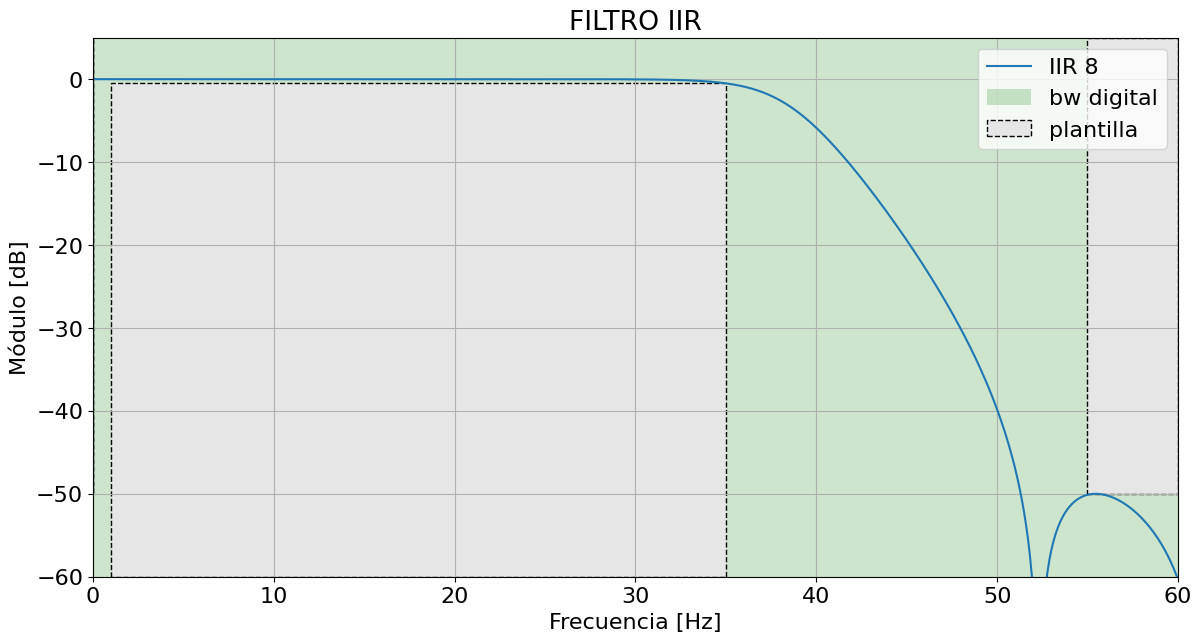

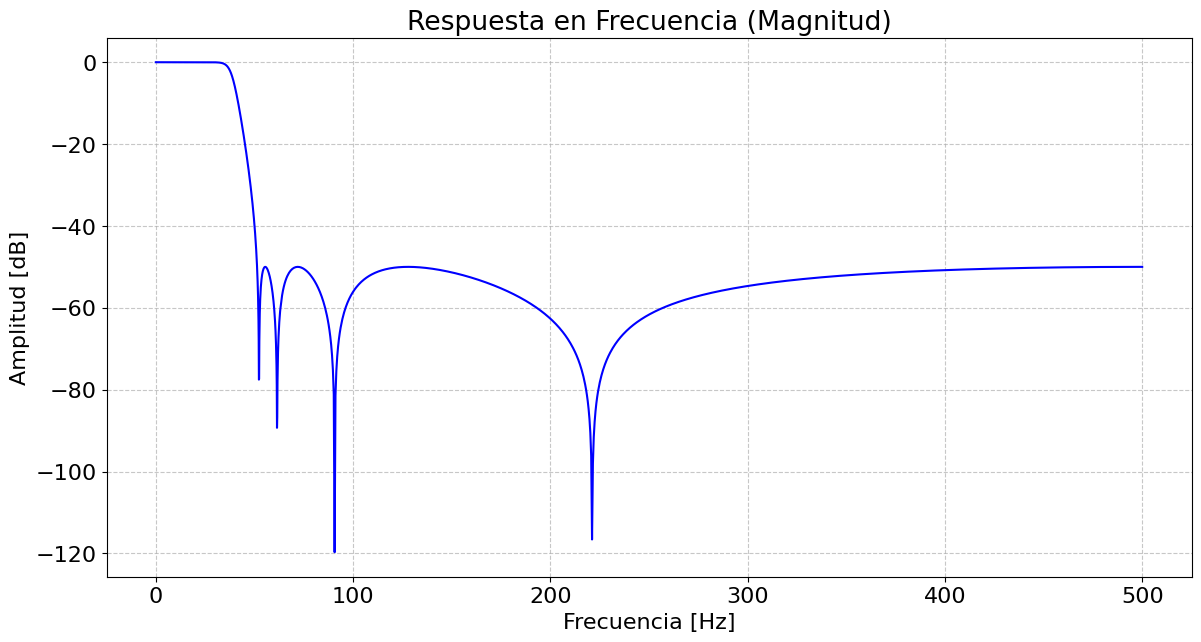

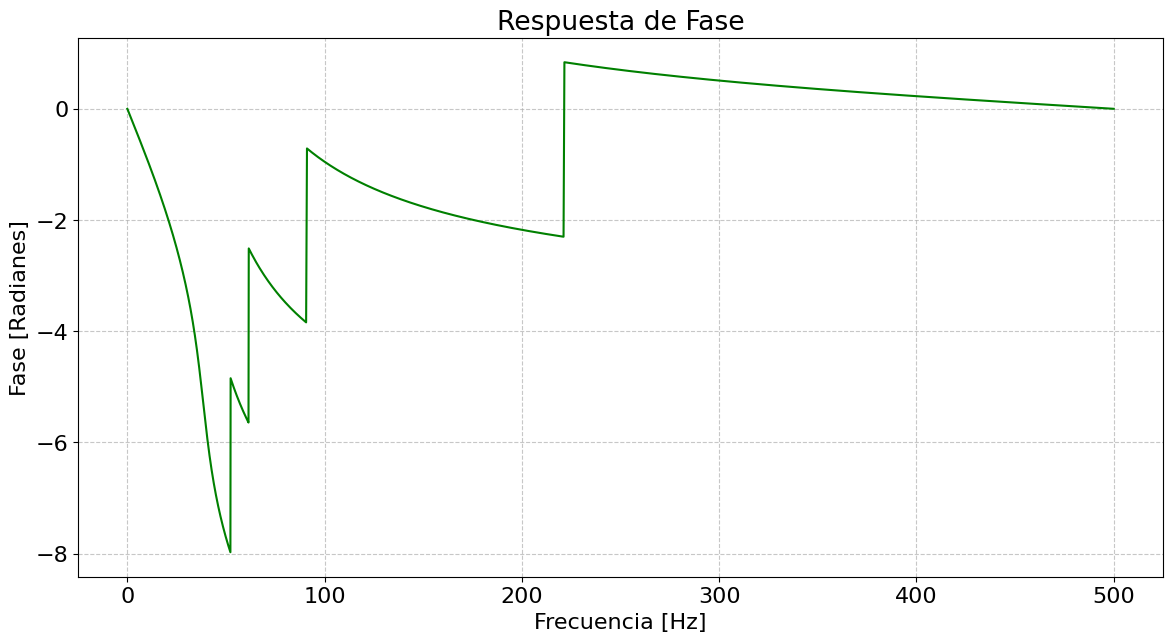

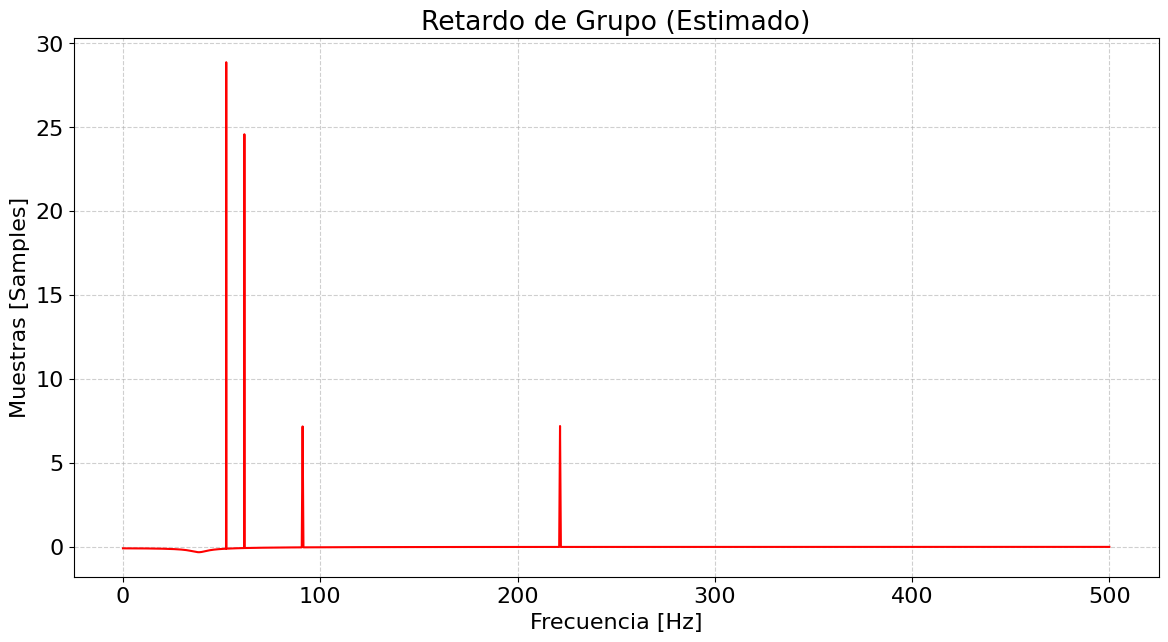

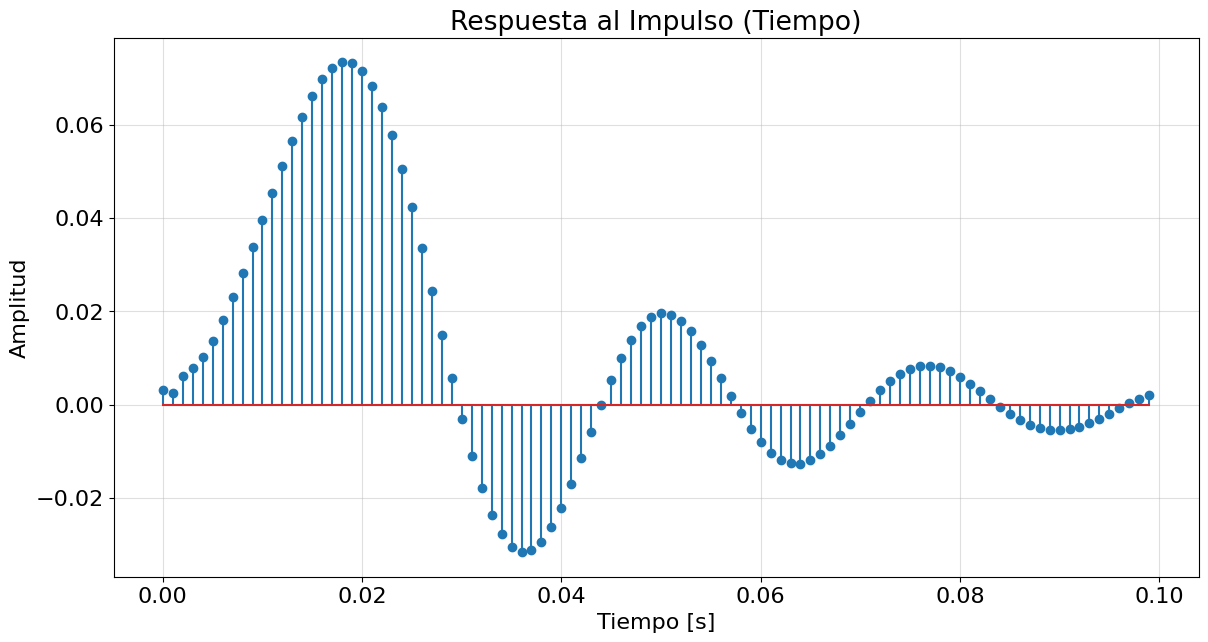

In [7]:
plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.plot(w_rad, 20*np.log10(np.abs(h_iir)+1e-12), label = 'IIR {:d}' .format(sos_iir.shape[0] * 2) )

plt.title('FILTRO IIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
plt.axis([0, 60, -60, 5 ])

axes_hdl = plt.gca()

plot_plantilla(filter_type = 'bandpass', fpass = (wp1, wp2), fstop =  (ws1, ws2), ripple = ripple, attenuation = atenuacion, fs = fs)
_ = axes_hdl.legend()

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.title('Respuesta en Frecuencia (Magnitud)')
plt.plot(w_rad, 20*np.log10(np.abs(h_iir)+1e-12), 'b')
plt.ylabel('Amplitud [dB]')
plt.xlabel('Frecuencia [Hz]')
plt.grid(True, which='both', linestyle='--', alpha=0.7)

plt.figure(2, figsize=(fig_sz_x, fig_sz_y))

phase_rad = np.unwrap(np.angle(h_iir))

plt.title('Respuesta de Fase')
plt.plot(w_rad, phase_rad, 'g')
plt.ylabel('Fase [Radianes]')
plt.xlabel('Frecuencia [Hz]')
plt.grid(True, which='both', linestyle='--', alpha=0.7)

plt.figure(3, figsize=(fig_sz_x, fig_sz_y))

d_omega = np.diff(w_rad)
d_phi = np.diff(phase_rad)
group_delay = d_phi / d_omega
freqs_gd = w_rad[1:]

plt.plot(freqs_gd, group_delay, color='red')
plt.title('Retardo de Grupo (Estimado)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Muestras [Samples]')
plt.grid(True, linestyle='--', alpha=0.6)

plt.figure(4, figsize=(fig_sz_x, fig_sz_y))

num_muestras = 100
impulso_entrada = np.zeros(num_muestras)
impulso_entrada[0] = 1.0
h_tiempo = sig.sosfilt(sos_iir, impulso_entrada)
t = np.arange(num_muestras) / fs

plt.stem(t, h_tiempo)
plt.title('Respuesta al Impulso (Tiempo)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid(True, alpha=0.4)

plt.show()

Podrá observarse que la respuesta de módulo es la propia de un filtro del tipo **cheby2**, y lo más interesante, y que reafirma lo explicado al comienzo, la fase no es para nada lineal. Esto, nos genera picos de retraso en diversas frecuencias, pero nos permite obtener un filtro útil con cuatro secciones de segundo órden, es decir, de órden 8.

En cuanto a la respuesta al impulso, al tener en frecuencia un módulo similar a un escalon, entonces es lógico obtener algo parecido a una **sinc** en el tiempo, que atenúa cada vez más para tiempos mayores.

#### **PARTE 2: IMPLEMENTACIÓN Y USO**

Para esta parte, se propuso tomar un archivo que contiene una señal propia de un "ECG", contaminada con ruido de diversas fuentes, y hacer uso del filtro recién diseñado para "limpiarla" de ruido.

Para el caso del filtro IIR, será indispensable implementar la ecuación de diferencias conocida:

\begin{equation}
y[k] = \frac{1}{a_0} \cdot \left( \sum_{m = 0}^M b_m x[k - m] - \sum_{n = 1}^N a_n y[k - n] \right)
\end{equation}

Esto lo lograremos por medio de la función **sosfilt**, visualizando los resultados en diferentes zonas de interés, para poder evaluar que tan bien se comporta el filtro diseñado. Primero revisaremos zonas de alta contaminación, verificando la eficiencia del filtrado, y luego de baja contaminación, determinando que tan inocuo es el filtro en su banda de paso. En ambos casos, se busca que la señal de ECG no sea alterada en su morfología, debido a que esto imposibilitaría su uso como método de diagnóstico. Los resultados se observan a continuación.

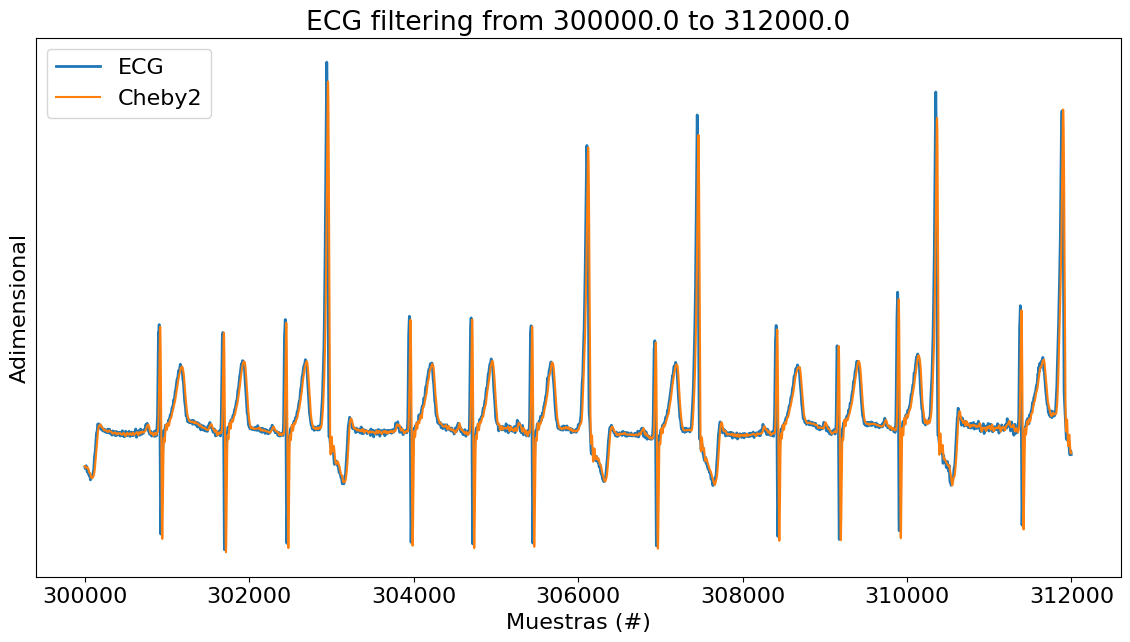

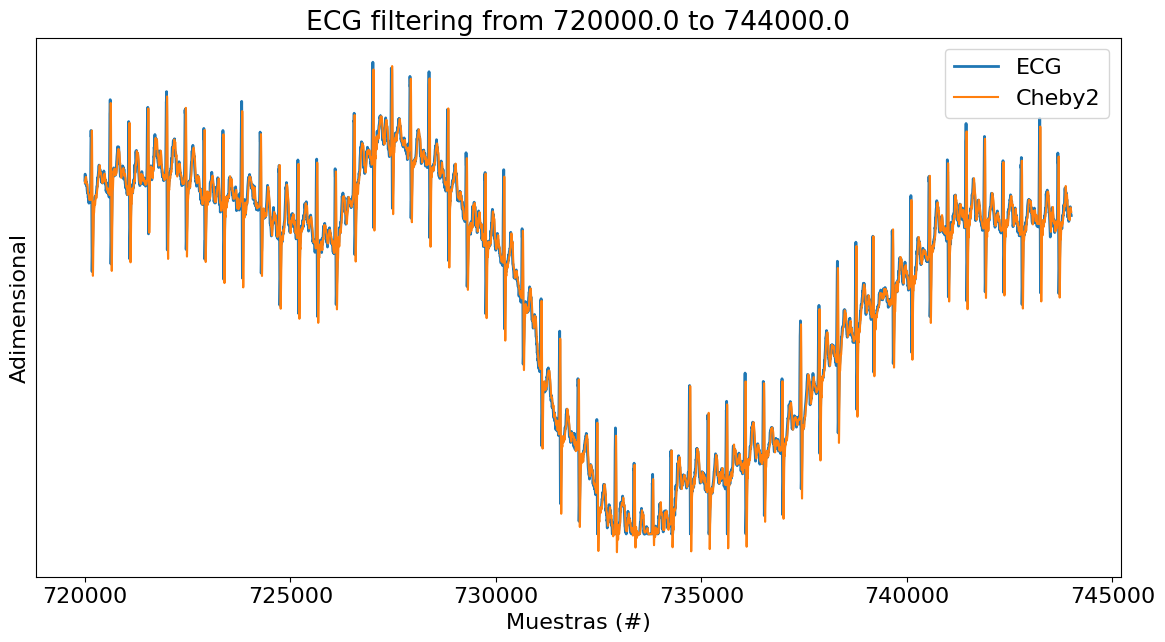

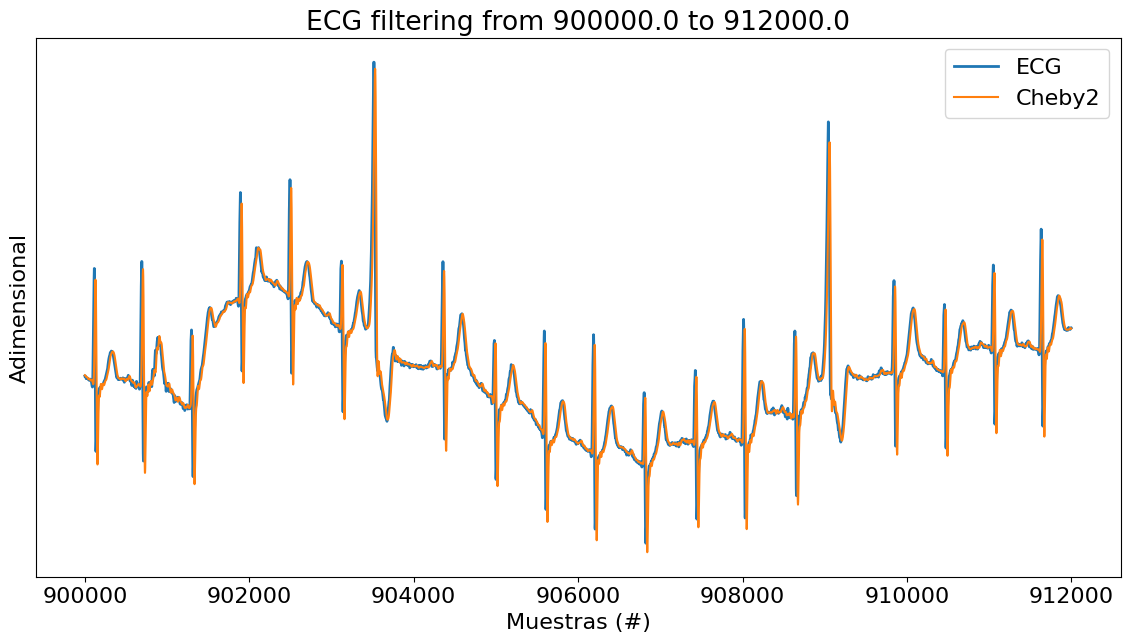

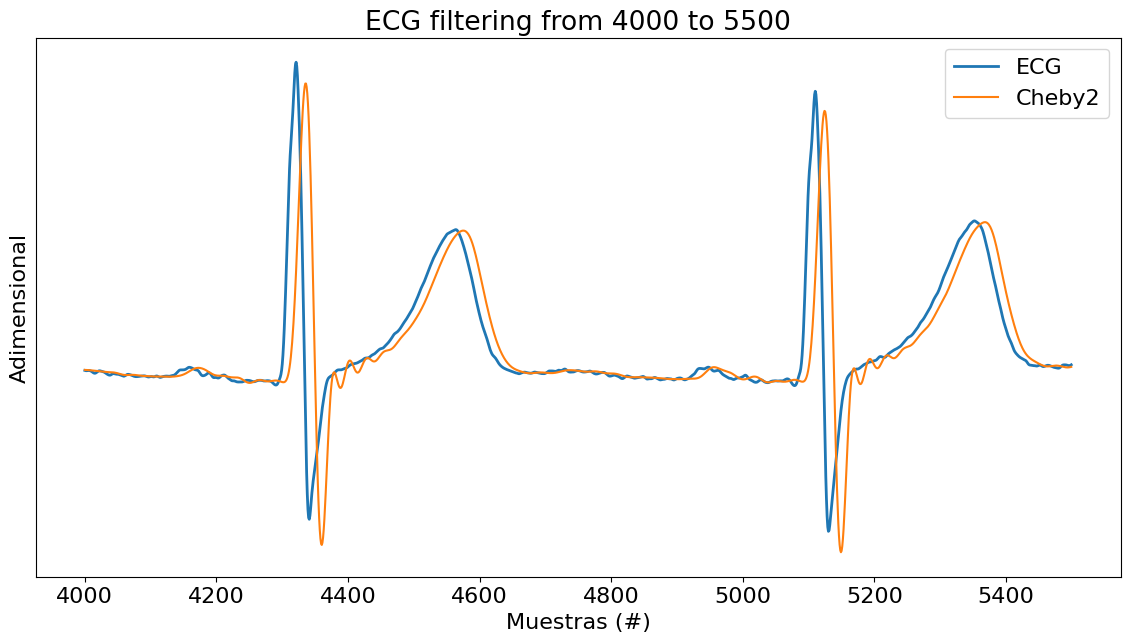

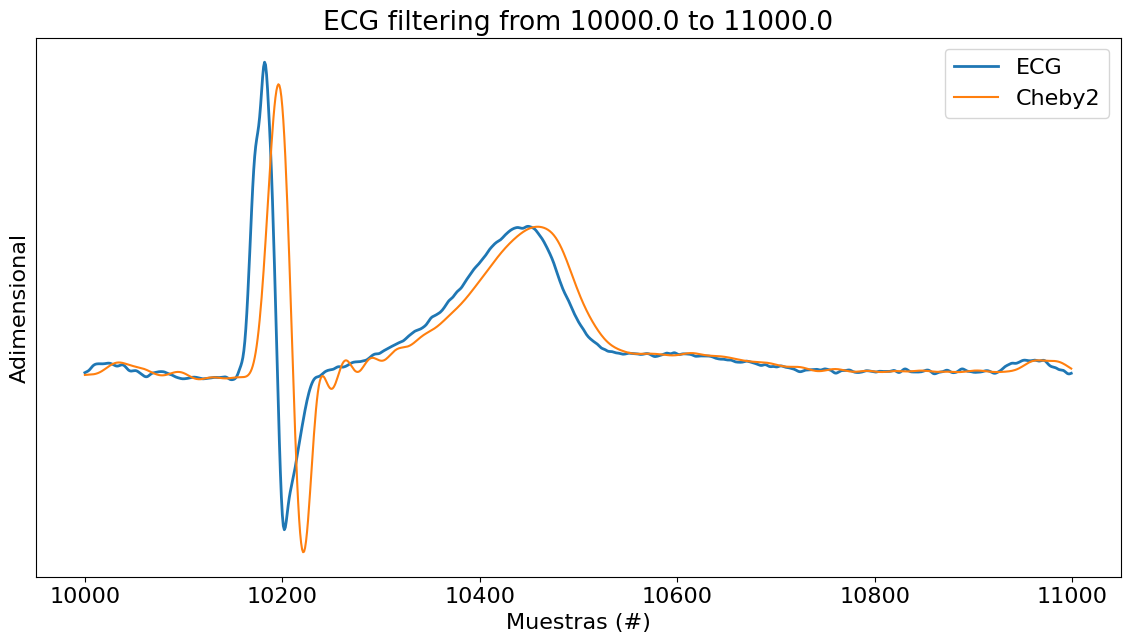

In [9]:
# IIR
ECG_f_iir = sig.sosfilt(sos_iir, ecg_one_lead)

# Segmentos de interés con ALTA contaminación

regs_interes = ( 
        np.array([5, 5.2]) *60*fs, # minutos a muestras
        np.array([12, 12.4]) *60*fs, # minutos a muestras
        np.array([15, 15.2]) *60*fs, # minutos a muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, ECG_f_iir[zoom_region], label='Cheby2')
    
    plt.title('ECG filtering from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

regs_interes = ( 
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, ECG_f_iir[zoom_region], label='Cheby2')
    
    plt.title('ECG filtering from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

Como podemos observar, se da una exacta similitud entre la señal de ECG y la filtrada por el diseño para las zonas de alta contaminación. En las otras zonas de baja contaminación, se observa que la forma de onda es casi exacta, pero presenta un leve desfasaje en muestras.

Para corregir esto, aplicaremos la técnica de filtrado bidireccional por medio de la función **filtfilt**. Es una técnica sumamente conveniente al momento de filtrar digitalmente una señal, dado que evita por completo cualquier distorsión de fase. Esto afecta principalmente a los filtros IIR, donde las distorsiones pueden ser notorias.

Aplicar esta ténica equivale a pasar la señal dos veces por el mismo filtro, por lo que la atenuación en banda de rechazo será el doble que la del fitro original. Por este motivo, debe relajarse a la mitad la atenuación original, pero exigir más el ripple en banda de paso, también reduciéndolo a la mitad. De esta forma, obtenemos el siguiente filtro y resultados de filtrado, observando que tanto para zonas de alta como de baja contaminación tenemos un filtrado óptimo, sin distorsiones de la señal original.

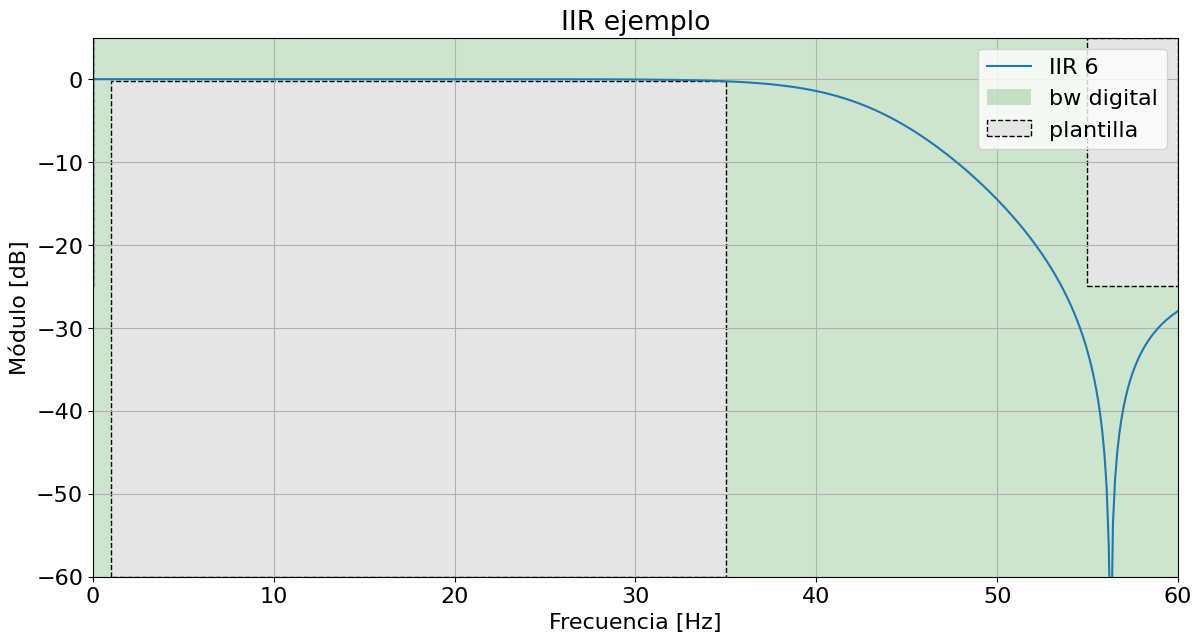

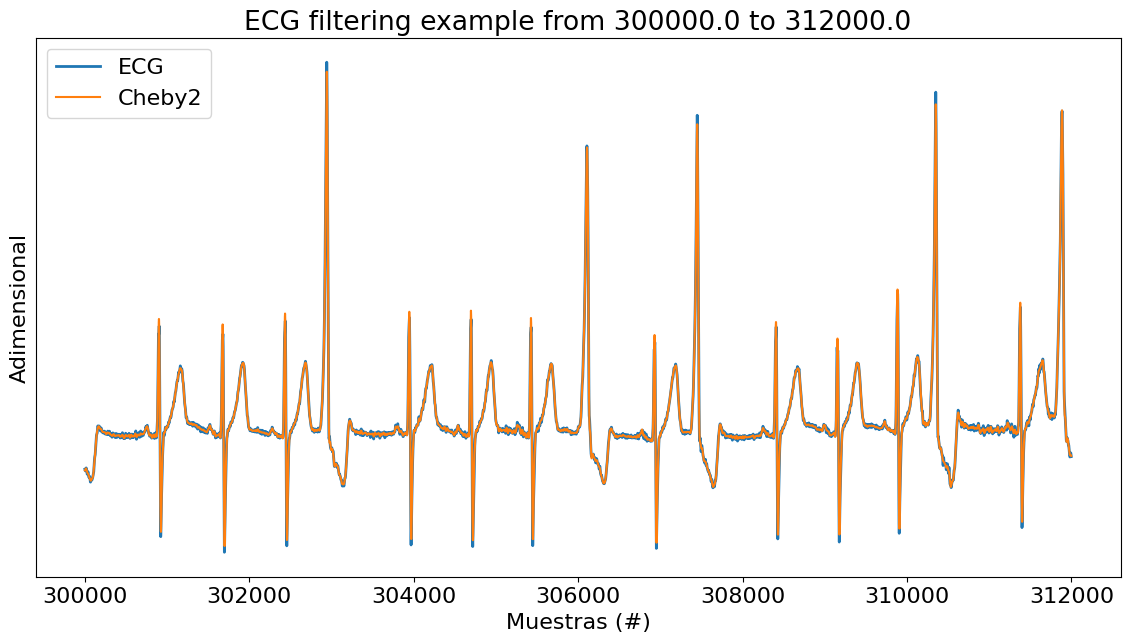

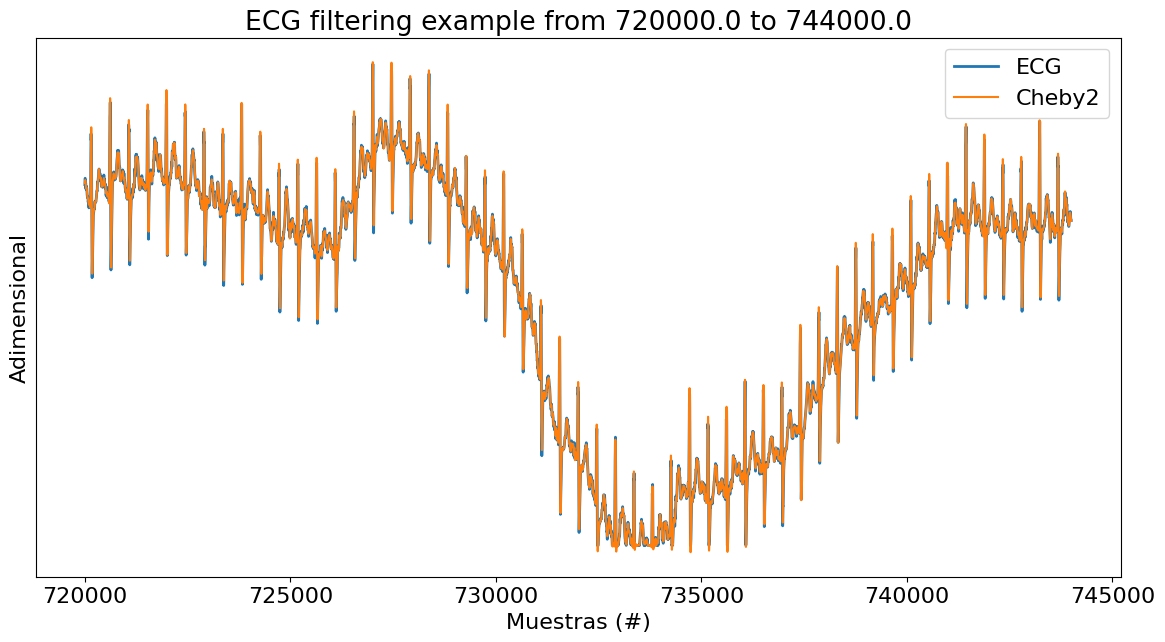

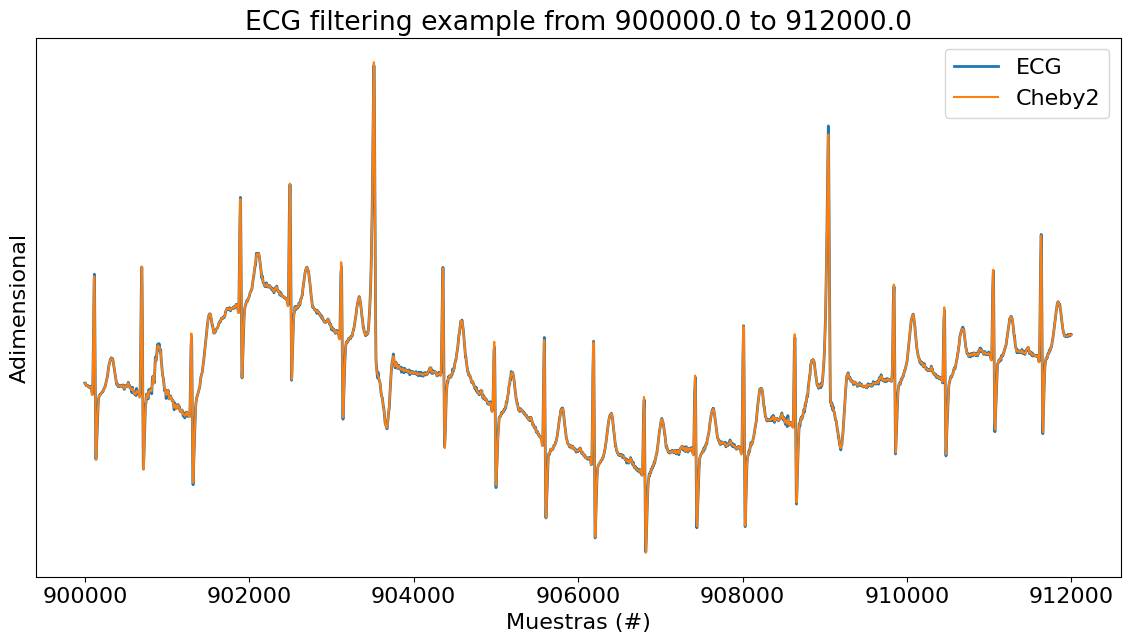

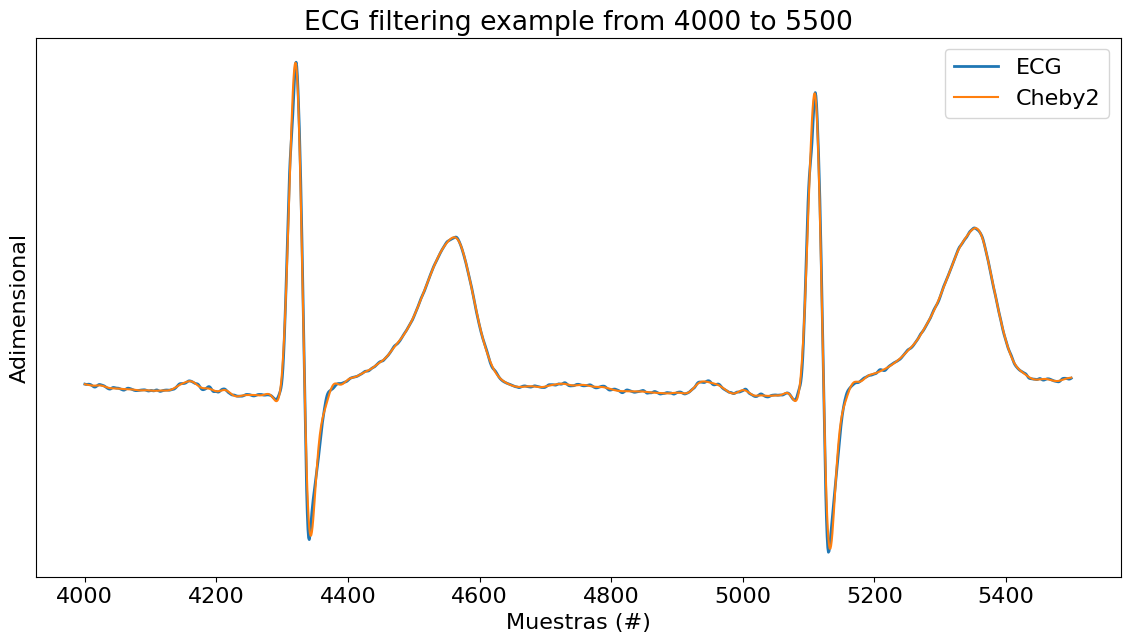

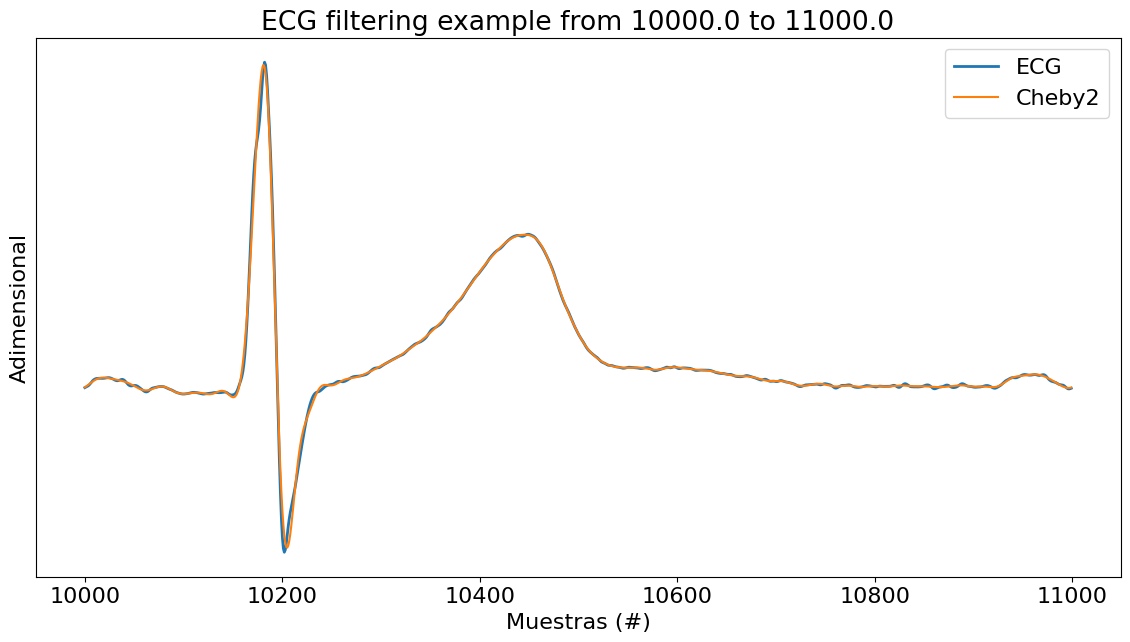

In [10]:
ripple = 0.25 # dB
atenuacion = 25 # dB

sos_iir = sig.iirdesign(wp= wp2, ws=ws2, gpass=ripple, gstop=atenuacion, output='sos', analog=False, ftype='cheby2', fs = fs)

w_rad  = np.append(np.logspace(-3, 0.8, 1000), np.logspace(0.9, 1.8, 1000) )
w_rad  = np.append(w_rad, np.linspace(64, nyq_frec, 1000, endpoint=True) )

w_rad, h_iir = sig.freqz_sos(sos_iir, worN=w_rad, fs = fs)

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.plot(w_rad, 20*np.log10(np.abs(h_iir)+1e-12), label = 'IIR {:d}' .format(sos_iir.shape[0] * 2) )

plt.title('IIR ejemplo')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
plt.axis([0, 60, -60, 5 ])

axes_hdl = plt.gca()

plot_plantilla(filter_type = 'bandpass', fpass = (wp1, wp2), fstop =  (ws1, ws2), ripple = ripple, attenuation = atenuacion, fs = fs)
_ = axes_hdl.legend()

# Procedemos al filtrado
ECG_f_iir = sig.sosfiltfilt(sos_iir, ecg_one_lead)

# Segmentos de interés
regs_interes = ( 
        np.array([5, 5.2]) *60*fs, # minutos a muestras
        np.array([12, 12.4]) *60*fs, # minutos a muestras
        np.array([15, 15.2]) *60*fs, # minutos a muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', lw=2)
    plt.plot(zoom_region, ECG_f_iir[zoom_region], label='Cheby2')
    
    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

regs_interes = ( 
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', lw=2)
    plt.plot(zoom_region, ECG_f_iir[zoom_region], label='Cheby2')
    
    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

### **FILTRO FIR**

Los filtros FIR son aquellos que presentan una Respuesta Finita al Impulso, que, al contrario de los IIR, no utilizan el concepto de recursividad. Esto significa que al introducir un impulso en la entrada, la salida oscilará por un tiempo, hasta llegar a un cero absoluto, donde permanecerá.

La ecuación de diferencias que los describe es la misma que para los IIR, excepto que todos los coeficientes "$a_n$" que acompañan las salidas anteriores valen cero:

\begin{equation}
y[k] = \frac{1}{a_0} \cdot \left( \sum_{m = 0}^M b_m x[k - m] \right)
\end{equation}

Es muy fácil de implementar matemáticamente, ya que suelen ser una suma ponderada de valores pasados, que no tienen realimentación, por lo que siempre serán estables.

Sin embargo, a diferencia de los IIR, para implementar respuestas de módulo con cortes abruptos, requieren de muchos coeficientes, lo que implica un costo computacional mucho más elevado. De todas formas, si los coeficientes son simétricos, entonces presentarán **Fase Lineal**, lo cual representa una gran ventaja, ya que implica un retraso de grupo constante, garantizando que todas las frecuencias sean retrasadas un mismo tiempo, sin provocar distorsiones en la forma de onda.

En el caso que se presentará, se utilizó el **Método de Ventanas**, que permite aproximarse a la forma del "Filtro Ideal" cuadrado, pero sin generar una forma de onda en tiempo que resulte ser una "sinc" que se atenúa en el infinito. Por el contrario, se multiplica dicha sinc por una curva suave, que atenúa los bordes suavemente hasta llegar a cero. En este caso en particular, se utilizó una **Ventana de Hamming**, que cancela casi todo el rizado del primer lóbulo de la sinc, ofreciendo un excelente equilibrio entre limpieza y selectividad.

#### **PARTE 1: DISEÑO DE FILTROS**

Al igual que para el filtro IIR, se comenzó por incorporar los módulos que nos ayudarán a implementar el filtro deseado. Se cargó el archivo del "ECG" a utilizar, se definió la frecuencia de muestreo "$f_s$" a utilizar, y se estableció el ripple, la atenuación, y las frecuencias de las bandas requeridas:

In [11]:
# Inicialización e importación de módulos

# Módulos para Jupyter
import warnings
warnings.filterwarnings('ignore')

# Módulos importantantes
import scipy.signal as sig
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from pytc2.sistemas_lineales import plot_plantilla

# Tamaño de las figuras
fig_sz_x = 14
fig_sz_y = 7

# Tamaño de la tipografía
fig_font_size = 16

plt.rcParams.update({'font.size':fig_font_size})

###
## Señal de ECG registrada a 1 kHz, con contaminación de diversos orígenes.
###

# para listar las variables que hay en el archivo
#io.whosmat('ecg.mat')
mat_struct = sio.loadmat('ecg.mat')

ecg_one_lead = mat_struct['ecg_lead']
ecg_one_lead = ecg_one_lead.flatten()
cant_muestras = len(ecg_one_lead)

fs = 1000 # Hz
nyq_frec = fs / 2

# Plantilla

# filter design
ripple = 0.5 # dB
atenuacion = 40 # dB

# FILTRO FIR

ws_1 = .1 #Hz
wp_1 = 1 #Hz
wp_2 = 35.0 #Hz
ws_2 = 36 #Hz           //Predistorsionado en 36 Hz, original en 45 Hz

# se fija una cantidad de coeficientes para la respuesta del FIR
cant_coeficientes = 3501

La selección de los valores de frecuencia se realizó mediante otro método de prueba y error, en este caso, predistorsionando la respuesta del filtro en 36 Hz, garantizando una correcta atenuación a la frecuencia pedida de 45 Hz. Junto con esto, se determinó la cantidad de coeficientes a emplear en el filtro, resultando en 3500.

Posteriormente, haciendo uso de la función **firwin2** de *scipy.signal*, que nos entrega un array con los coeficientes del numerador del filtro deseado. También se utilizó **freqz** para obtener la respuesta en frecuencia del filtro, junto con el vector de frecuencias que nos permitirá graficarlo.

A continuación, se observan la respuesta de módulo, de fase, de retardo de grupo y la respuesta al impulso.

In [12]:
# algoritmo de diseño, se obtienen los coeficientes del numerador
num_win = sig.firwin2(cant_coeficientes, freq = (0, ws_1, wp_1, wp_2 , ws_2, nyq_frec), gain = (0, 0, 1, 1, 0, 0) , window='hamming', antisymmetric = True, fs = fs )

# coeficientes del denominador
den = 1.0

# muestreo el filtro donde me interesa verlo según la plantilla.
w  = np.append(np.logspace(-1.8, 0.8, 250), np.logspace(0.9, 1.6, 250) )
w  = np.append(w, np.linspace(110, nyq_frec, 100, endpoint=True) )

w, hh_win = sig.freqz(num_win, den, worN=w, fs = fs)

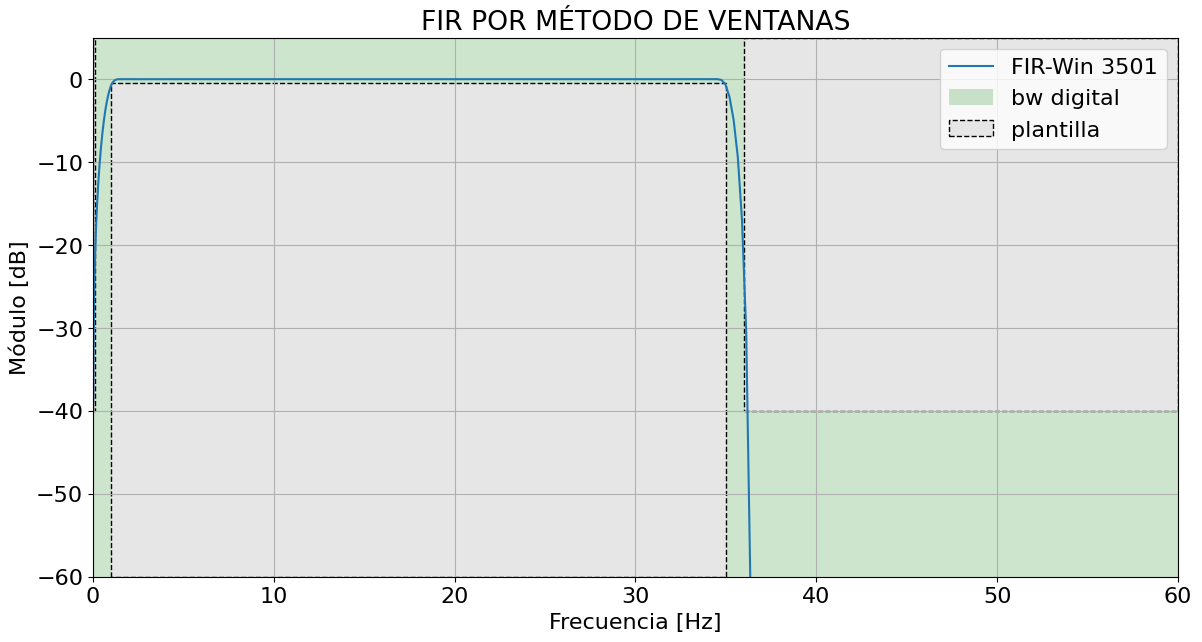

Valor máximo de la respuesta: 0.05130875890567166
Valor en t=0: -1.6187363214657533e-06


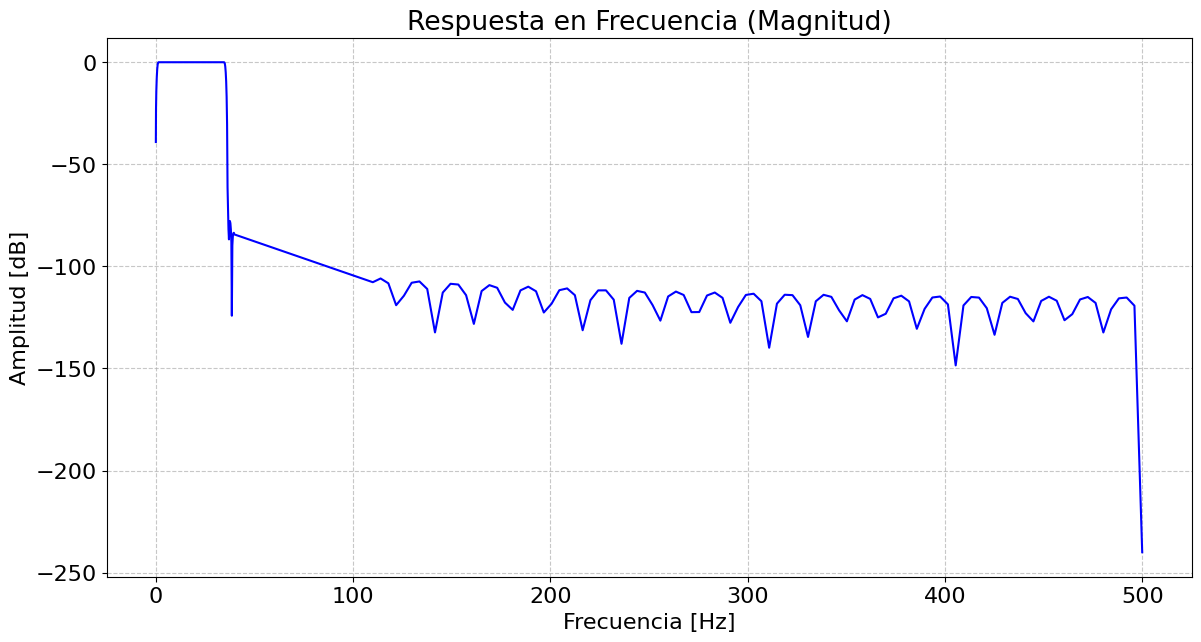

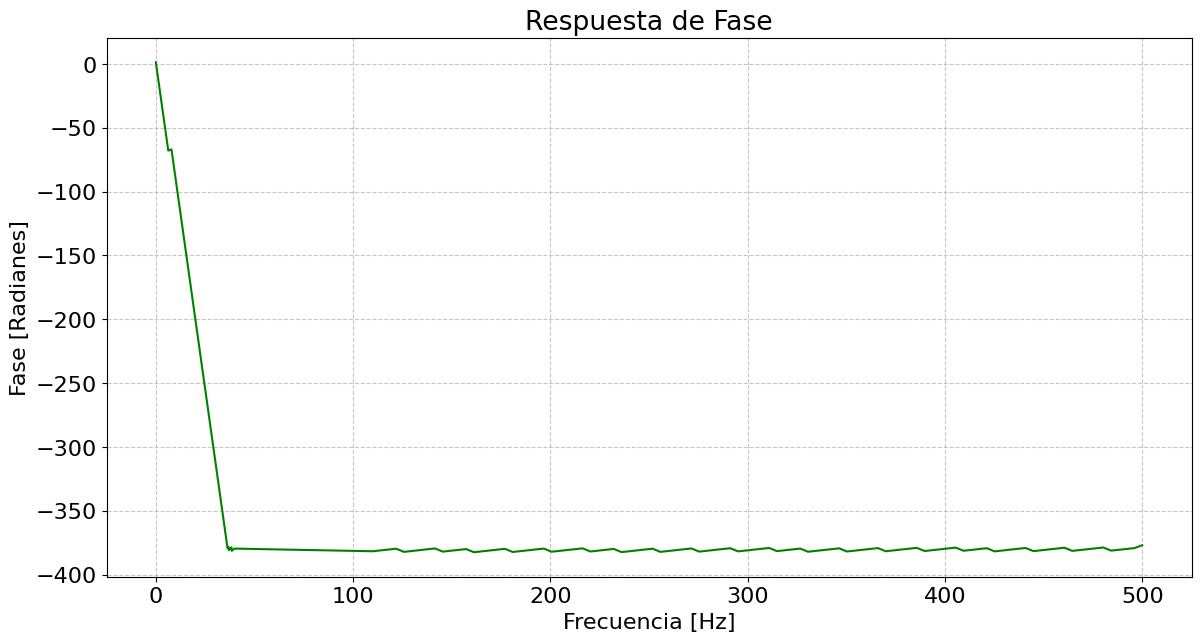

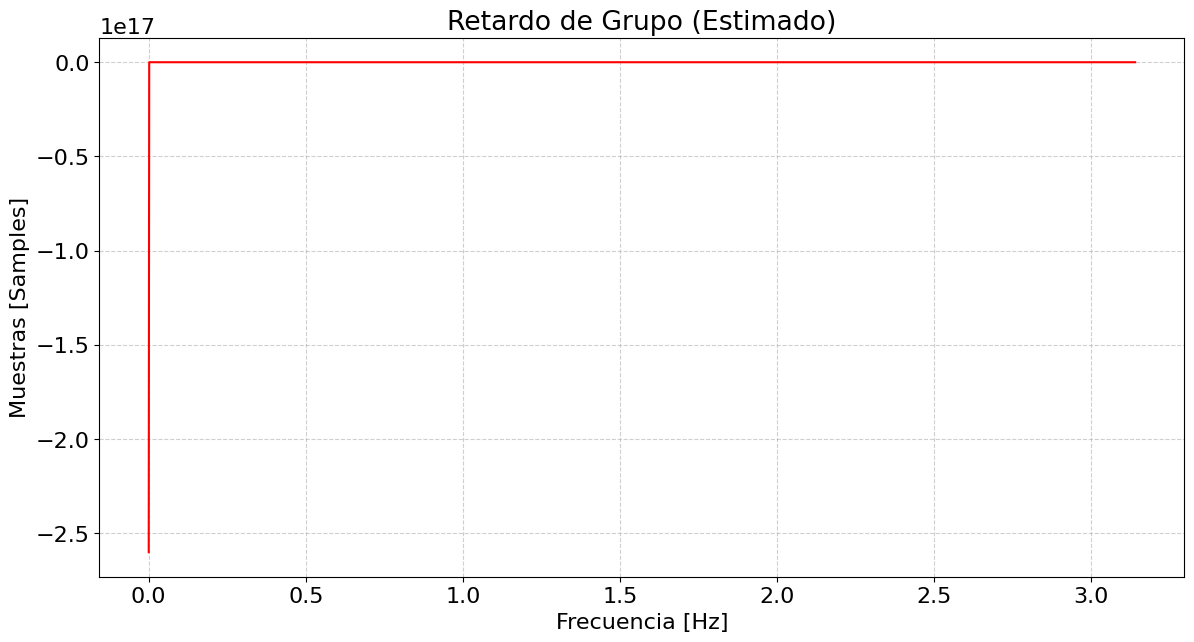

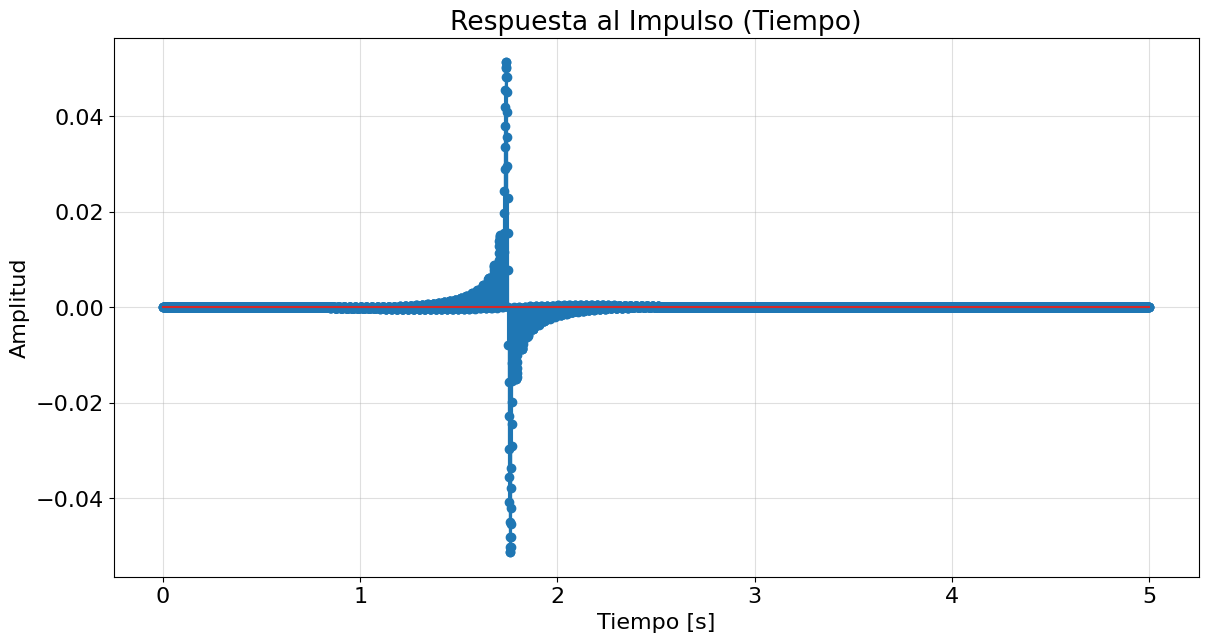

In [13]:
plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.plot(w, 20 * np.log10(abs(hh_win)), label='FIR-Win {:d}'.format(num_win.shape[0]))

plt.title('FIR POR MÉTODO DE VENTANAS')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
plt.axis([0, 60, -60, 5 ])

axes_hdl = plt.gca()
axes_hdl.legend()

plot_plantilla(filter_type = 'bandpass', fpass = (wp_1, wp_2), fstop =  (ws_1, ws_2), ripple = ripple, attenuation = atenuacion, fs = fs)

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.title('Respuesta en Frecuencia (Magnitud)')
plt.plot(w, 20*np.log10(np.abs(hh_win)+1e-12), 'b')
plt.ylabel('Amplitud [dB]')
plt.xlabel('Frecuencia [Hz]')
plt.grid(True, which='both', linestyle='--', alpha=0.7)

plt.figure(2, figsize=(fig_sz_x, fig_sz_y))

phase_rad = np.unwrap(np.angle(hh_win))

plt.title('Respuesta de Fase')
plt.plot(w, phase_rad, 'g')
plt.ylabel('Fase [Radianes]')
plt.xlabel('Frecuencia [Hz]')
plt.grid(True, which='both', linestyle='--', alpha=0.7)

plt.figure(3, figsize=(fig_sz_x, fig_sz_y))

w_gd, group_delay = sig.group_delay((num_win, den), w=2048)

plt.plot(w_gd, group_delay, color='red')
plt.title('Retardo de Grupo (Estimado)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Muestras [Samples]')
plt.grid(True, linestyle='--', alpha=0.6)

plt.figure(4, figsize=(fig_sz_x, fig_sz_y))

num_muestras = 5000
impulso = np.zeros(num_muestras)
impulso[0] = 1.0

# Filtramos la delta para obtener la respuesta al impulso
h_n = sig.lfilter(num_win, den, impulso)
tiempo = np.arange(num_muestras) / fs # Eje de tiempo

print(f"Valor máximo de la respuesta: {np.max(h_n)}")
print(f"Valor en t=0: {h_n[0]}")

plt.stem(tiempo, h_n)
plt.title('Respuesta al Impulso (Tiempo)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid(True, alpha=0.4)

plt.show()

Puede observarse que la respuesta de módulo se asemeja enormemente a un escalon en las bandas de frecuencia establecidas, cumpliendo con la plantilla establecida. Por otra parte, la fase resulta ser lineal decreciente, lo que nos induce un retardo de grupo constante, con un único pico de retraso en la muestra cero.

Luego, la respuesta al impulso presenta un evento principal de oscilación aproximadamente en 1,75 segundos, lo cual se corresponde con el retraso inducido por el filtro, visto en los próximos códigos. Esto se debe a que los filtros FIR de fase lineal tienen un retardo de grupo constante igual a la mitad de su orden $\left( \frac{N}{2} \right)$.

El filtro deja pasar "pocas" frecuencias (de 1 a 35 Hz comparado con los 500 Hz disponibles), la energía en el tiempo no se concentra en un pico alto de 1.0, sino que se esparce a lo largo de esos 3.5 segundos.

Como conclusión, podemos decir que al procesar datos grabados, no se presenta ningún inconveniente, excepto que la salida estará desplazada 1,75 segundos, lo cual será tenido en cuenta para el siguiente análisis, donde se procede a filtrar la señal de ECG con lo diseñado.

#### **PARTE 2: IMPLEMENTACIÓN Y USO**

Para esta parte, se propuso tomar un archivo que contiene una señal propia de un "ECG", contaminada con ruido de diversas fuentes, y hacer uso del filtro recién diseñado para "limpiarla" de ruido.

Esto lo lograremos por medio de la función **lfilter**, que puede utilizarse para filtros FIR de cualquier tamaño, visualizando los resultados en diferentes zonas de interés, para poder evaluar que tan bien se comporta el filtro diseñado. Primero revisaremos zonas de alta contaminación, verificando la eficiencia del filtrado, y luego de baja contaminación, determinando que tan inocuo es el filtro en su banda de paso. En ambos casos, se busca que la señal de ECG no sea alterada en su morfología, debido a que esto imposibilitaría su uso como método de diagnóstico. Los resultados se observan a continuación.

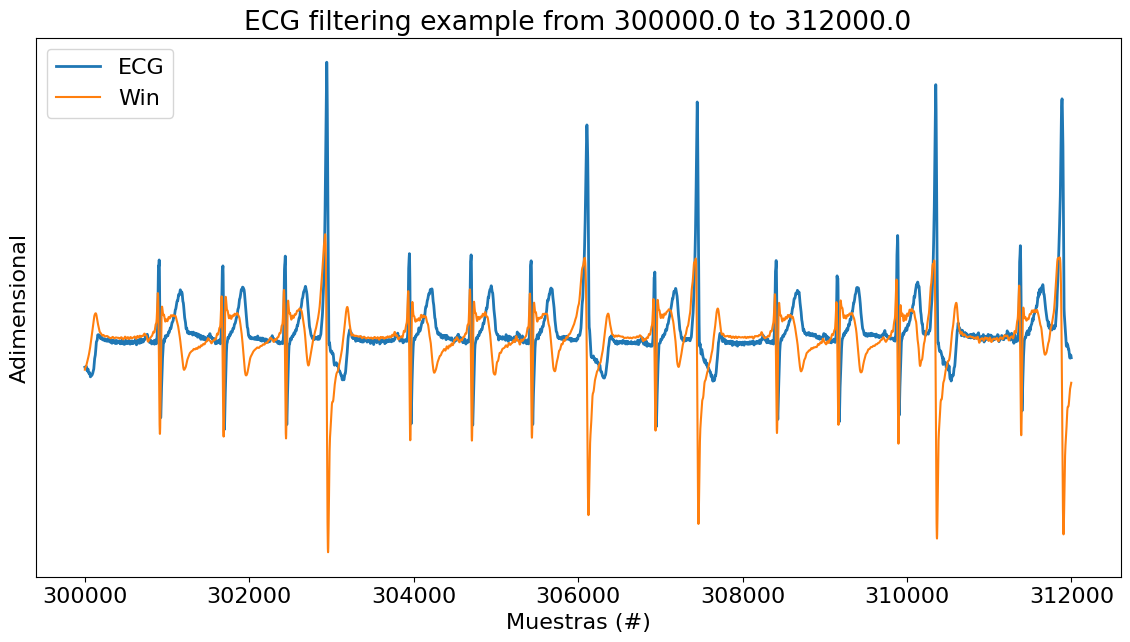

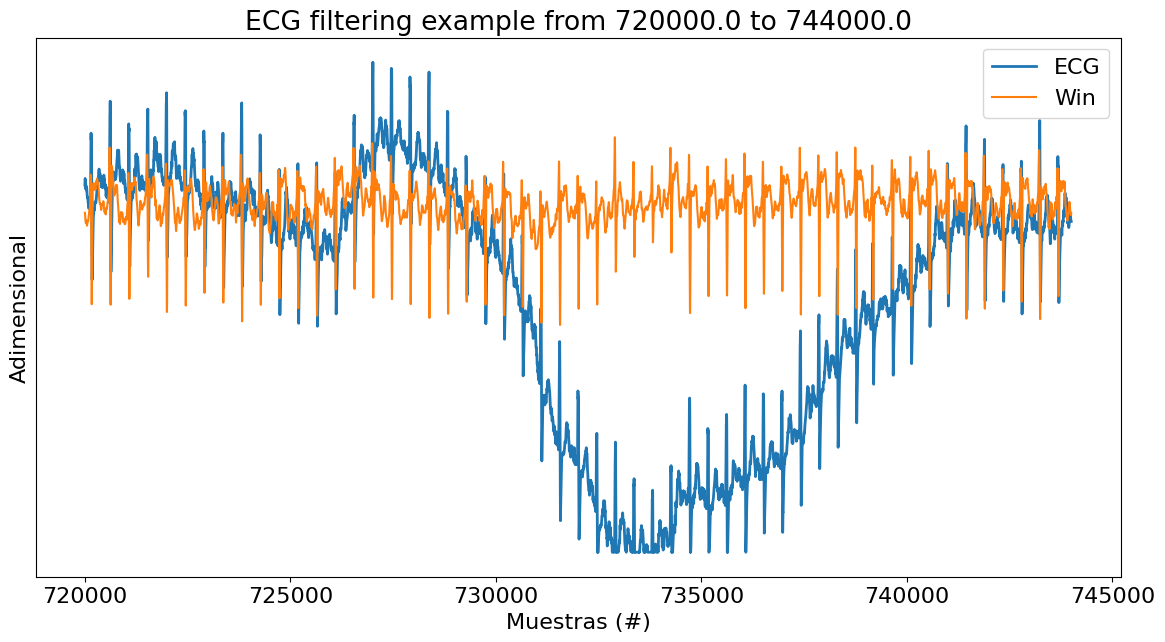

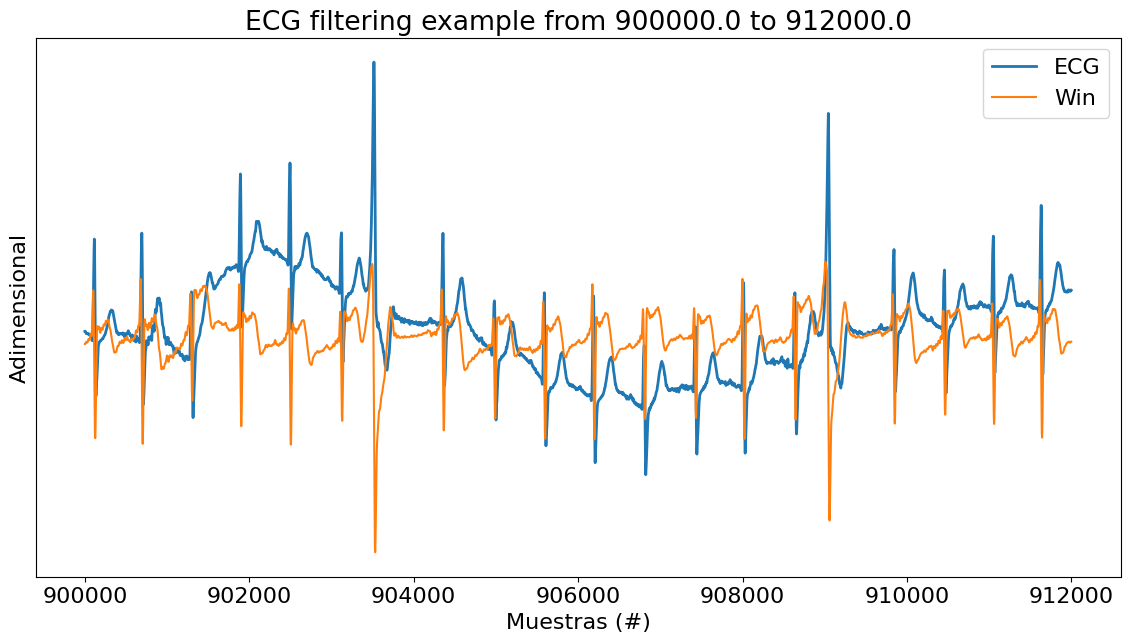

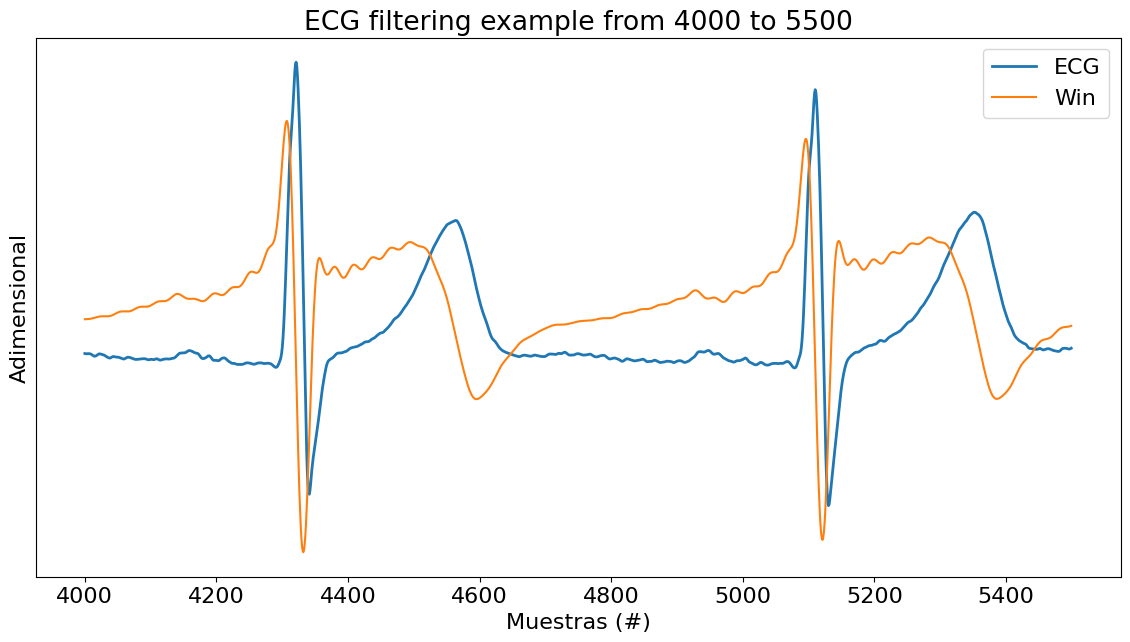

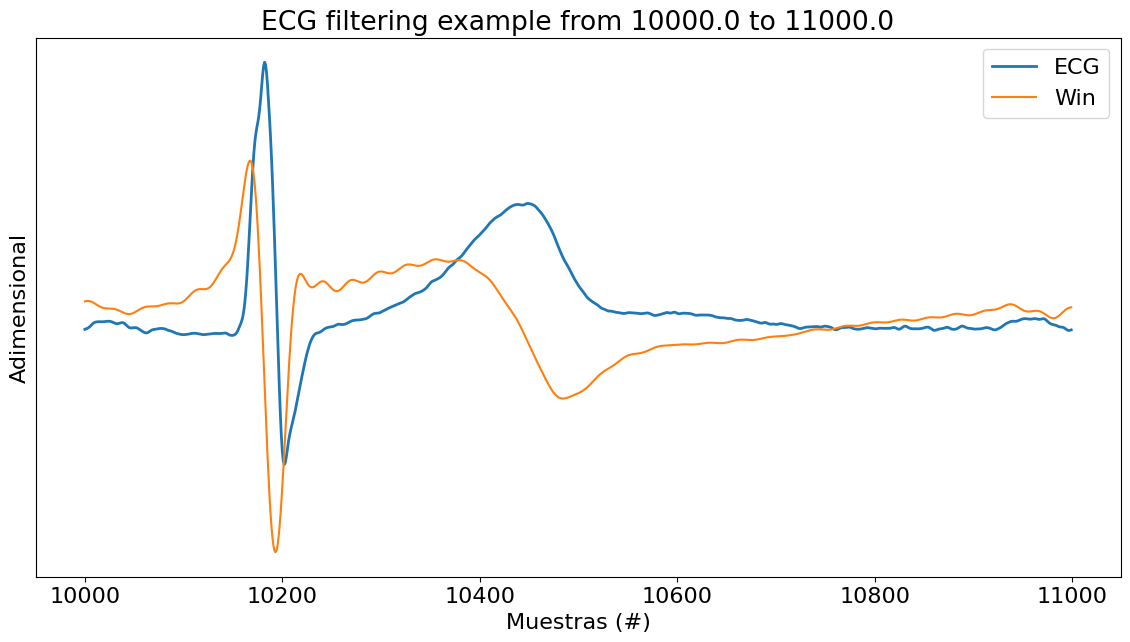

In [14]:
# FIR
ECG_f_win = sig.lfilter(num_win, den, ecg_one_lead)

# demora = int(...)
# calcule la demora para cada caso, dicha demora adelantará la señal de salida, como puede ver más abajo.
demora = 1750

# Segmentos de interés con ALTA contaminación

regs_interes = ( 
        np.array([5, 5.2]) *60*fs, # minutos a muestras
        np.array([12, 12.4]) *60*fs, # minutos a muestras
        np.array([15, 15.2]) *60*fs, # minutos a muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, ECG_f_win[zoom_region + demora], label='Win')
    
    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

regs_interes = ( 
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
    plt.plot(zoom_region, ECG_f_win[zoom_region + demora], label='Win')
    
    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

Es posible observar una coincidencia de los picos en las zonas de alta y baja contaminación, pero con una cierta inversión de la forma de onda, lo cual podría implicar una importante distorsión. Para solucionar esto, volveremos a aplicar la técnica de filtrado bidireccional.

Nuevamente, aplicar esta ténica equivale a pasar la señal dos veces por el mismo filtro, por lo que la atenuación en banda de rechazo será el doble que la del fitro original. Por este motivo, debe relajarse a la mitad la atenuación original, pero exigir más el ripple en banda de paso, también reduciéndolo a la mitad. De esta forma, obtenemos el siguiente filtro y resultados de filtrado, observando que tanto para zonas de alta como de baja contaminación tenemos un filtrado óptimo, sin distorsiones de la señal original.

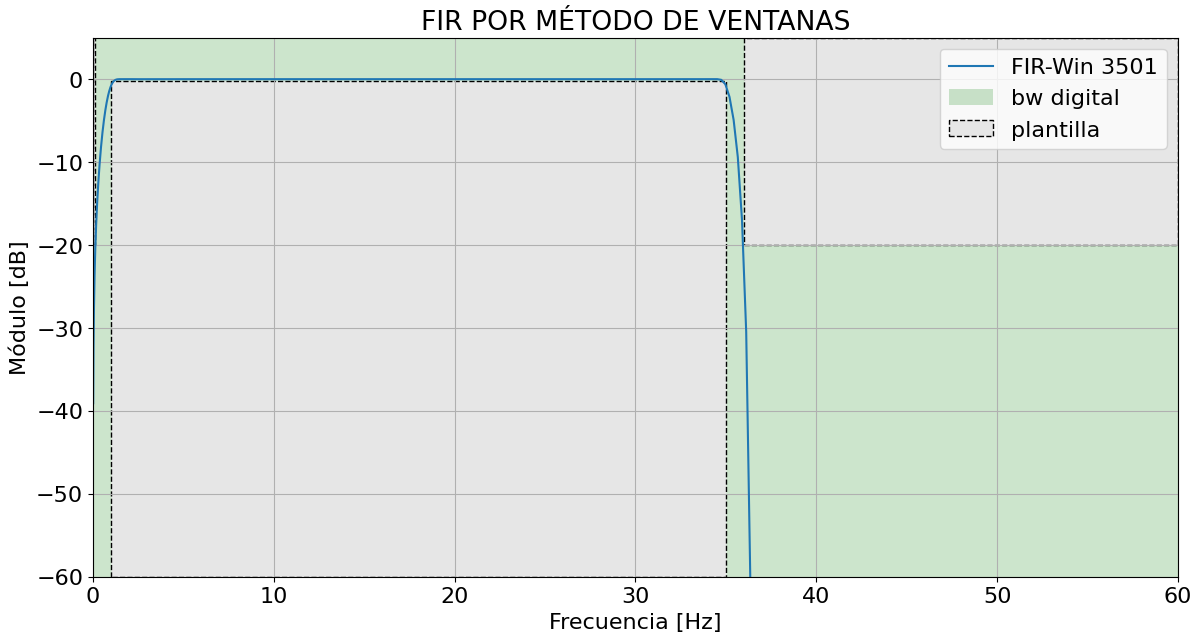

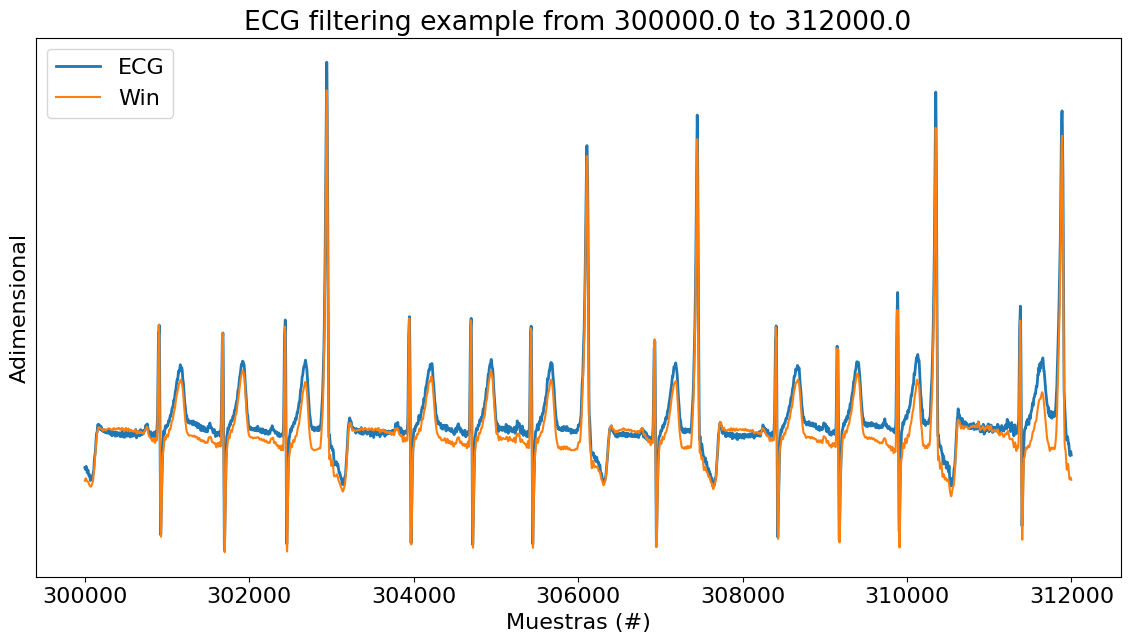

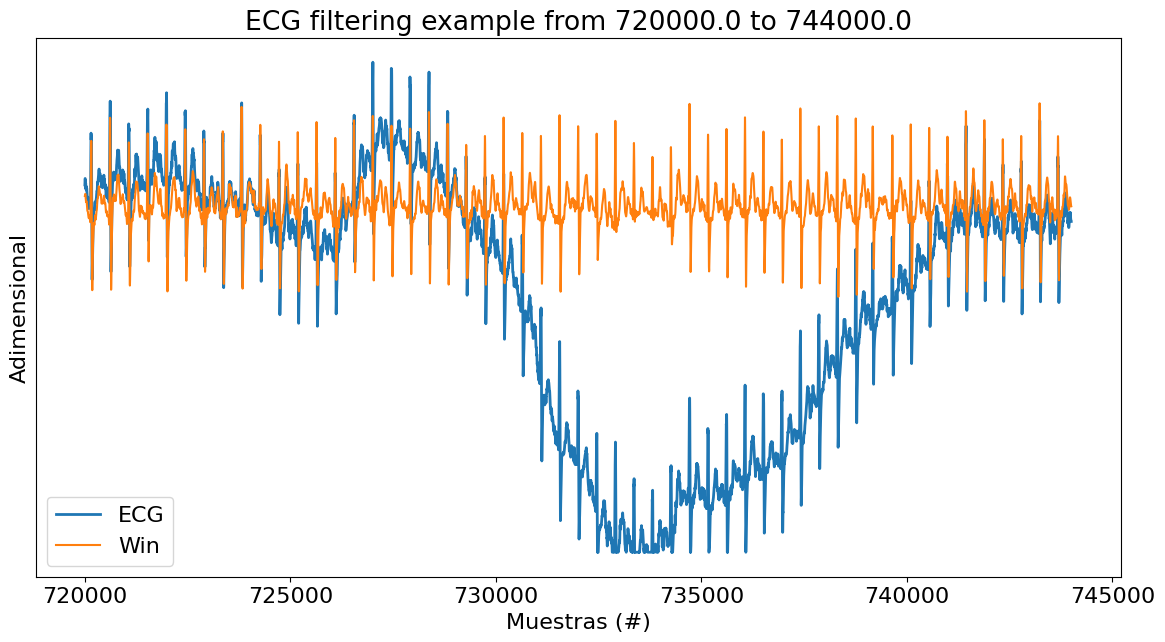

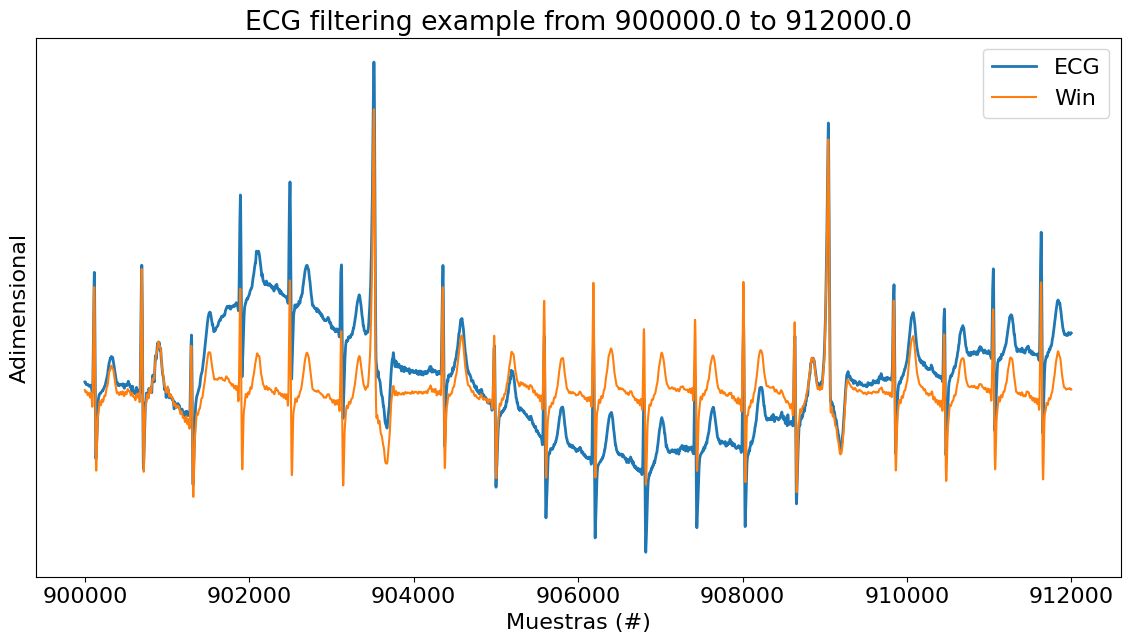

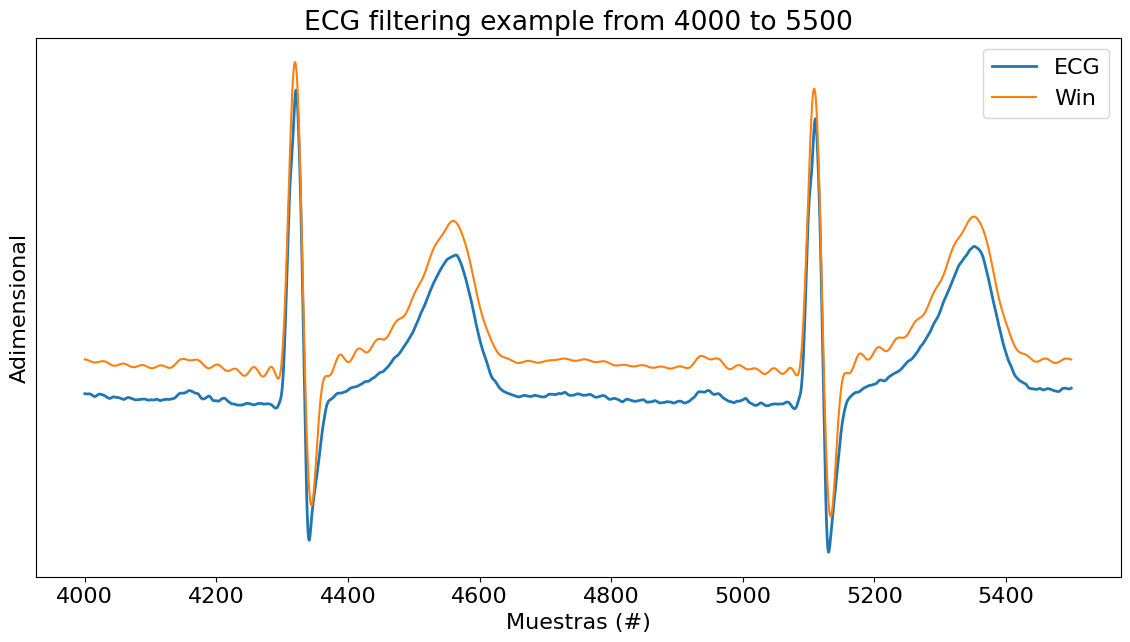

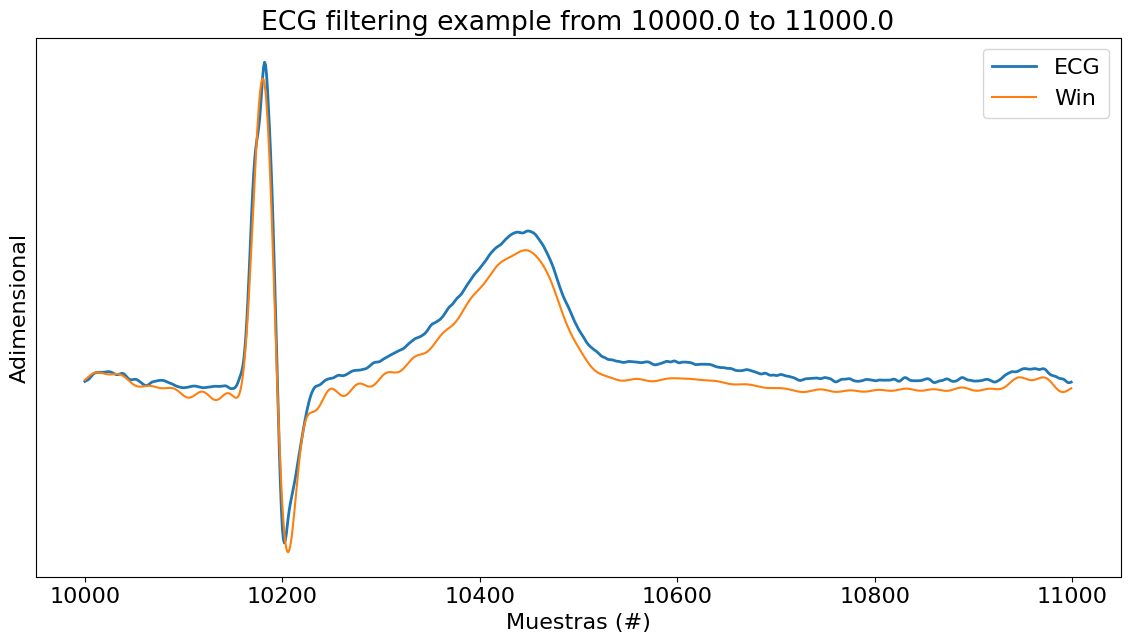

In [15]:
# filter design
ripple = 0.25 # dB
atenuacion = 20 # dB

# algoritmo de diseño, se obtienen los coeficientes del numerador
num_win = sig.firwin2(cant_coeficientes, freq = (0, ws_1, wp_1, wp_2 , ws_2, nyq_frec), gain = (0, 0, 1, 1, 0, 0) , window='hamming', antisymmetric = True, fs = fs )

# coeficientes del denominador
den = 1.0

# muestreo el filtro donde me interesa verlo según la plantilla.
w  = np.append(np.logspace(-1.8, 0.8, 250), np.logspace(0.9, 1.6, 250) )
w  = np.append(w, np.linspace(110, nyq_frec, 100, endpoint=True) )

w, hh_win = sig.freqz(num_win, den, worN=w, fs = fs)

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.plot(w, 20 * np.log10(abs(hh_win)), label='FIR-Win {:d}'.format(num_win.shape[0]))

plt.title('FIR POR MÉTODO DE VENTANAS')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
plt.axis([0, 60, -60, 5 ])

axes_hdl = plt.gca()
axes_hdl.legend()

plot_plantilla(filter_type = 'bandpass', fpass = (wp_1, wp_2), fstop =  (ws_1, ws_2), ripple = ripple, attenuation = atenuacion, fs = fs)

# Procedemos al filtrado

ECG_f_win = sig.filtfilt(num_win, den, ecg_one_lead)

# Segmentos de interés
regs_interes = ( 
        np.array([5, 5.2]) *60*fs, # minutos a muestras
        np.array([12, 12.4]) *60*fs, # minutos a muestras
        np.array([15, 15.2]) *60*fs, # minutos a muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', lw=2)
    plt.plot(zoom_region, ECG_f_win[zoom_region], label='Win')
    
    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

regs_interes = ( 
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', lw=2)
    plt.plot(zoom_region, ECG_f_win[zoom_region], label='Win')
    
    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

Podemos observar como la inversión de la forma de onda fue corregida, permitiendo obtener una señal de ECG más limpia luego del filtrado, aunque se siguien apreciando discrepancias, sobre todo en las zonas de alta contaminación.

Esto, podría deberse a problemas en la implementación, en el desarrollo del filtro, o bien a problemas numéricos por el amplio número de coeficientes empleados para el diseño.